# OIBSIP – Level 1 Task 1: Exploratory Data Analysis on Online Retail

**Dataset:** UCI Machine Learning Repository – Online Retail  
**Source file:** `data/Online Retail.xlsx`  
**Coverage:** 1 December 2010 to 9 December 2011  
**Important:** This is genuine historical transaction data supplied by UCI, not synthetic/demo data. Currency is treated as GBP based on the dataset documentation. The source contains no customer age, gender, or product-category field, so those requested cuts cannot be honestly calculated.

## Objective
Clean and explore transaction-level retail data, quantify revenue trends, identify leading products and markets, and provide evidence-based business recommendations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("/content/Online Retail.xlsx")
raw = pd.read_excel(DATA_PATH)
print("Raw shape:", raw.shape)
display(raw.head())
display(raw.dtypes)
display(raw.isna().sum().rename("missing_values"))


Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


,missing_values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


## 1. Data cleaning

Rules used:
- Remove cancelled invoices (invoice number starts with `C`).
- Remove rows with zero/negative quantity or unit price.
- Remove rows with missing product descriptions.
- Retain rows with missing CustomerID for overall revenue calculations; exclude them only from customer-level analysis.
- Calculate line revenue as `Quantity × UnitPrice`.

These are analytical filters, not edits to the original source file.


In [2]:
df = raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["Description"] = df["Description"].astype("string").str.strip()
df["Country"] = df["Country"].astype("string").str.strip()
df["IsCancelled"] = df["InvoiceNo"].str.startswith("C", na=False)

clean = df.loc[
    (~df["IsCancelled"]) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["Description"].notna())
].copy()

clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["Month"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["Quarter"] = clean["InvoiceDate"].dt.to_period("Q").astype(str)
clean["YearMonth"] = clean["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
clean["Hour"] = clean["InvoiceDate"].dt.hour
clean["Weekday"] = clean["InvoiceDate"].dt.day_name()

print("Raw rows:", len(raw))
print("Cancelled invoices:", int(df["IsCancelled"].sum()))
print("Rows retained for sales analysis:", len(clean))
print("Date range:", clean["InvoiceDate"].min(), "to", clean["InvoiceDate"].max())
print("Distinct invoices:", clean["InvoiceNo"].nunique())
print("Distinct customers (known IDs):", clean["CustomerID"].nunique())
print("Countries:", clean["Country"].nunique())


Raw rows: 541909
Cancelled invoices: 9288
Rows retained for sales analysis: 530104
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Distinct invoices: 19960
Distinct customers (known IDs): 4338
Countries: 38


## 2. Descriptive statistics

In [3]:
display(clean[["Quantity", "UnitPrice", "Revenue"]].describe().T)
for col in ["Quantity", "UnitPrice", "Revenue"]:
    print(f"{col}: mean={clean[col].mean():.2f}, median={clean[col].median():.2f}, mode={clean[col].mode().iloc[0]:.2f}, std={clean[col].std():.2f}")


,count,mean,std,min,25%,50%,75%,max
Quantity,530104.0,10.542037,155.524124,1.000,1.00,3.00,10.00,80995.00
UnitPrice,530104.0,3.907625,35.915681,0.001,1.25,2.08,4.13,13541.33
Revenue,530104.0,20.121871,270.356743,0.001,3.75,9.90,17.70,168469.60


Quantity: mean=10.54, median=3.00, mode=1.00, std=155.52
UnitPrice: mean=3.91, median=2.08, mode=1.25, std=35.92
Revenue: mean=20.12, median=9.90, mode=15.00, std=270.36


## 3. Monthly and quarterly revenue trends

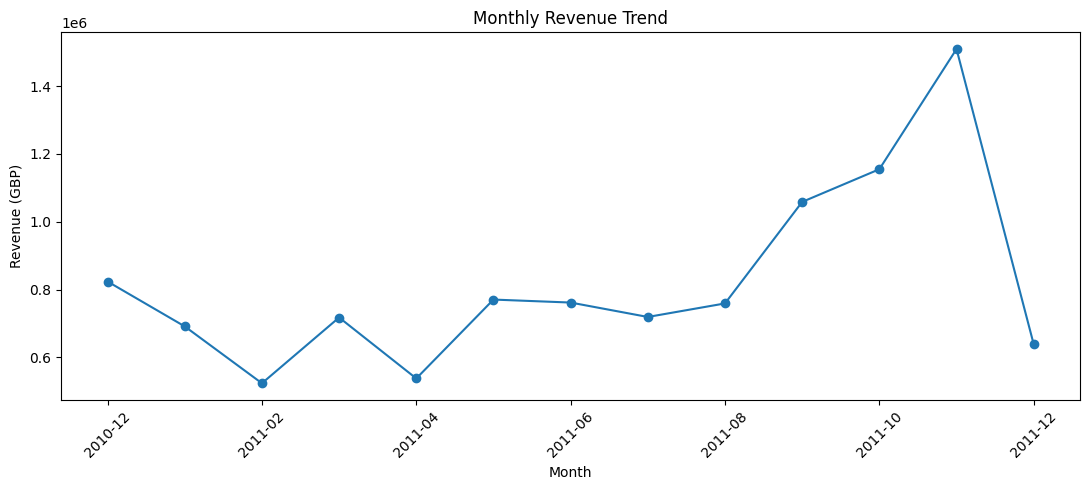

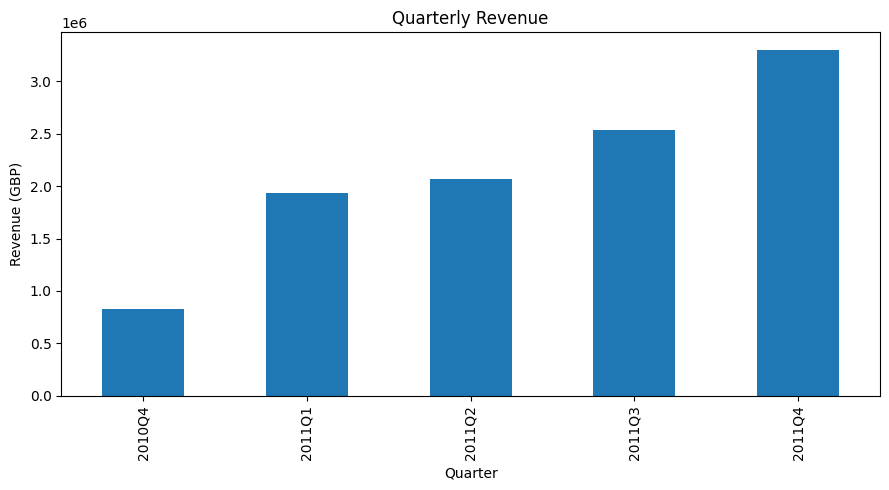

,Revenue
Month,
2011-11,1509496.330
2011-10,1154979.300
2011-09,1058590.172
2010-12,823746.140
2011-05,770536.020


,Revenue
Quarter,
2010Q4,823746.140
2011Q1,1932635.810
2011Q2,2070084.541
2011Q3,2536949.743
2011Q4,3303268.310


In [4]:
monthly = clean.groupby("Month")["Revenue"].sum().sort_index()
quarterly = clean.groupby("Quarter")["Revenue"].sum().sort_index()

monthly.plot(figsize=(11,5), marker="o", title="Monthly Revenue Trend")
plt.ylabel("Revenue (GBP)"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

quarterly.plot(kind="bar", figsize=(9,5), title="Quarterly Revenue")
plt.ylabel("Revenue (GBP)"); plt.tight_layout(); plt.show()

display(monthly.sort_values(ascending=False).head(5))
display(quarterly)


## 4. Best-selling products and country revenue

,Units_Sold,Revenue
Description,,
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,13841.85
JUMBO BAG RED RETROSPOT,48474,94340.05
WHITE HANGING HEART T-LIGHT HOLDER,37891,106292.77
POPCORN HOLDER,36761,34298.87
ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93
PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10
RABBIT NIGHT LIGHT,30788,66964.99


,Revenue
Country,
United Kingdom,9025222.084
Netherlands,285446.340
EIRE,283453.960
Germany,228867.140
France,209715.110
Australia,138521.310
Spain,61577.110
Switzerland,57089.900
Belgium,41196.340


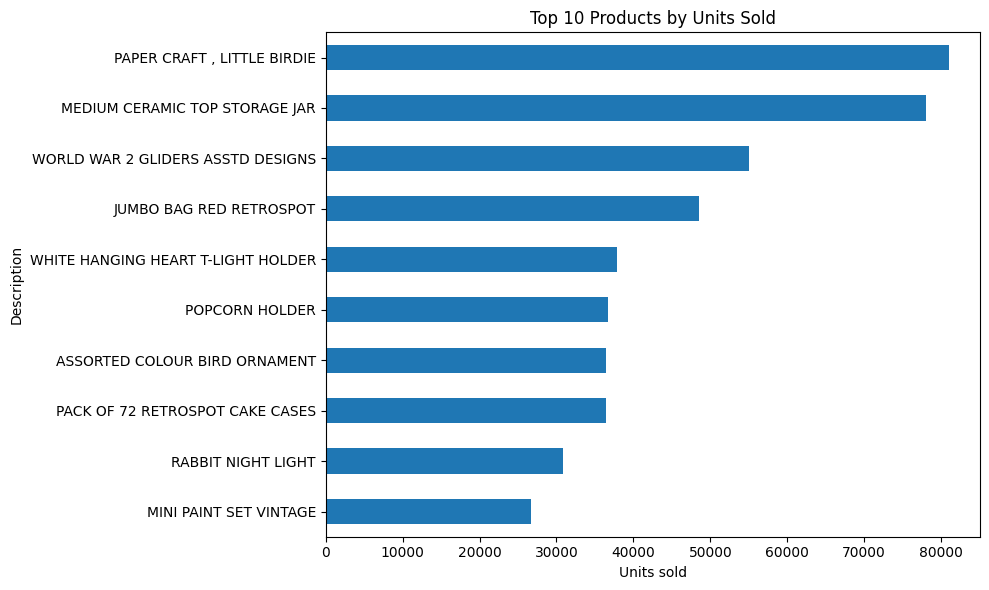

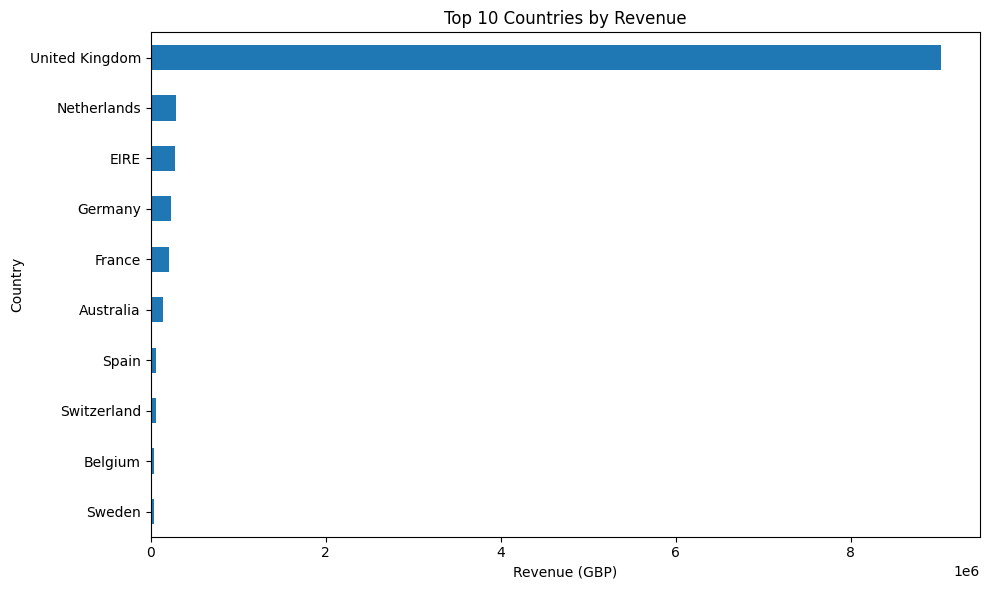

In [5]:
product_summary = (clean.groupby("Description")
    .agg(Units_Sold=("Quantity","sum"), Revenue=("Revenue","sum"))
    .sort_values("Units_Sold", ascending=False))
display(product_summary.head(10))

country_summary = clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
display(country_summary.head(10))

product_summary.head(10)["Units_Sold"].sort_values().plot(kind="barh", figsize=(10,6), title="Top 10 Products by Units Sold")
plt.xlabel("Units sold"); plt.tight_layout(); plt.show()

country_summary.head(10).sort_values().plot(kind="barh", figsize=(10,6), title="Top 10 Countries by Revenue")
plt.xlabel("Revenue (GBP)"); plt.tight_layout(); plt.show()


## 5. Customer analysis

CustomerID is missing on a portion of transactions. The customer-level ranking below uses only rows with a known CustomerID. Age and gender are not present in the source and are therefore not inferred.


In [6]:
known_customers = clean.dropna(subset=["CustomerID"])
customer_summary = known_customers.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
print("Rows with missing CustomerID:", int(clean["CustomerID"].isna().sum()))
print("Share missing CustomerID:", f"{clean['CustomerID'].isna().mean():.1%}")
display(customer_summary.head(10))


Rows with missing CustomerID: 132220
Share missing CustomerID: 24.9%


,Revenue
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194550.79
16446.0,168472.50
14911.0,143825.06
12415.0,124914.53
14156.0,117379.63
17511.0,91062.38
16029.0,81024.84


## 6. Correlation and additional analysis

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.003773,0.907338
UnitPrice,-0.003773,1.000000,0.137404
Revenue,0.907338,0.137404,1.000000


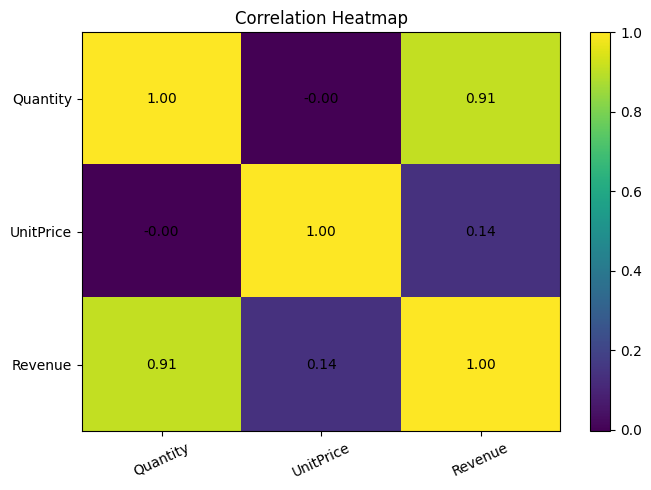

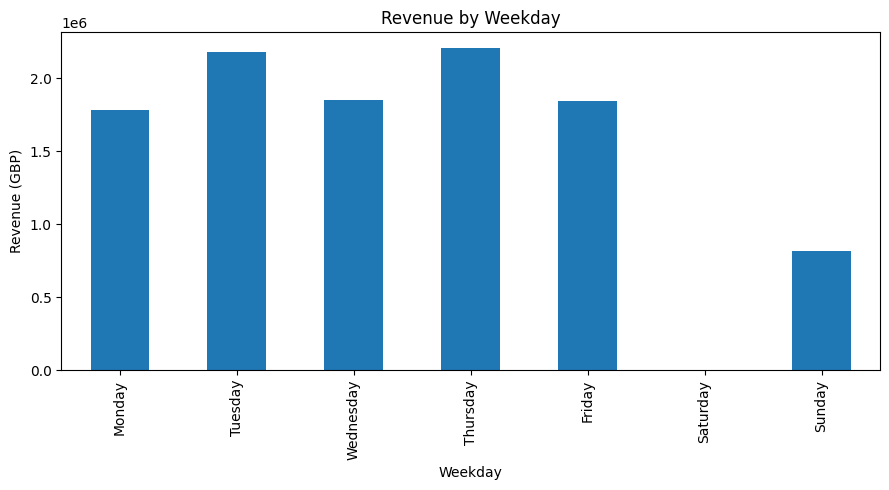

In [7]:
corr = clean[["Quantity","UnitPrice","Revenue"]].corr()
display(corr)
plt.figure(figsize=(7,5))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=25)
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center")
plt.title("Correlation Heatmap"); plt.colorbar(); plt.tight_layout(); plt.show()

weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_sales = clean.groupby("Weekday")["Revenue"].sum().reindex(weekday_order)
weekday_sales.plot(kind="bar", figsize=(9,5), title="Revenue by Weekday")
plt.ylabel("Revenue (GBP)"); plt.tight_layout(); plt.show()


## 7. Findings and recommendations

The figures should be interpreted as **line-item revenue** calculated from quantity × unit price. They are not audited financial statements or profit.

1. The United Kingdom is the dominant market in this dataset; consider protecting availability and customer experience there while testing growth in other markets.
2. November 2011 is the strongest month in the observed period; plan inventory and fulfilment capacity ahead of seasonal peaks.
3. The leading products by units sold are useful candidates for stock availability monitoring and bundle testing.
4. CustomerID is missing for a meaningful share of retained rows; improve customer identification at checkout to strengthen retention and lifetime-value analysis.
5. Review cancellation/return patterns separately before making margin or product-quality decisions; this sales-only cleaning intentionally excludes cancelled and non-positive lines.

## Limitations
- No customer age or gender fields.
- No product category field.
- No cost, discount, shipping, or profit fields; revenue is not profit.
- Dataset covers a historical period ending in December 2011.
- Customer-level analysis excludes records without CustomerID.
